## 문제 정의

- 뉴스그룹 본문을 입력받아 20개 카테고리 중 하나를 예측한다.
- 검증 지표는 정확도와 클래스별 precision, recall, F1이다.

## 시드 고정

시드(seed)는 난수의 시작값이야. Python, NumPy, PyTorch에 42를 설정해 데이터 섞기와 모델 초기화를 재현하기 쉽게 만든다. CUDA는 NVIDIA GPU를 사용할 때 선택된다.

In [8]:
# 필요한 패키지: numpy pandas matplotlib scikit-learn nltk wordcloud gensim torch tqdm
import copy
import hashlib
import os
import random
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.datasets import fetch_20newsgroups
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from wordcloud import WordCloud

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


## 데이터 수집

20 Newsgroups는 20개 카테고리에 속한 게시글 18,846건을 담고 있다. 헤더·푸터·인용문을 제거해 본문을 가져오고, 깊은 복사(`deepcopy`)로 원본과 작업용 데이터를 분리한다.

In [7]:
# https://scikit-learn.org/stable/datasets/real_world.html#the-20-newsgroups-text-dataset
original_data = fetch_20newsgroups(subset="all", remove=("headers", "footers", "quotes"))
data = copy.deepcopy(original_data)

In [10]:
# 데이터 설치 이후, 타입 확인
print(type(data))

<class 'sklearn.utils._bunch.Bunch'>


## 하기 내용은 스스로 공부를 위해서 상기 타입이 나오기 전에 기준서처럼 작성하는 셀입니다.

### 표(DataFrame)라면

행·열 크기와 열 이름을 확인하고 첫 몇 줄을 본다. 표 형태의 데이터를 만났을 때 이 셀의 주석을 풀어 실행한다.

In [ ]:
# print("크기(행, 열):", data.shape)
# print("열 이름들:", data.columns)
# print(data.head())

### Bunch 형태라면

Bunch는 이름으로 항목을 꺼낼 수 있는 묶음이다. 현재 20 Newsgroups는 이 형태라서 키 목록을 확인한 뒤 `data`(문서), `target`(정답 번호), `target_names`(카테고리 이름), `DESCR`(데이터 설명)을 확인한다.

In [11]:
print("들어있는 항목들:", data.keys())

들어있는 항목들: dict_keys(['data', 'filenames', 'target_names', 'target', 'DESCR'])


> 인사이트 : 'data' : 데이터, 'filenames' : 파일명, 'target_names' : 대상_이름, 'target' : 대상_설명, 'DESCR' : 설명

In [ ]:
# 글 본문 확인하기
texts = data.data
print("몇개의 글이 있나요?", len(texts)) # print 한 값에 2개를 표현할때 , 를 사용하여 표현해야 오류가 안남
print("첫 번째 글의 자료형은?", type(texts[0]))

몇개의 글이 있나요? 18846
첫 번째 글의 자료형은? <class 'str'>


In [22]:
labels = data.target
print("몇개의 정답이 있나요?", labels.shape)
print("첫 다섯 글의 정답 번호", labels[:5])

몇개의 정답이 있나요? (18846,)
첫 다섯 글의 정답 번호 [10  3 17  3  4]


In [ ]:
# 숫자로 표기되는 정답번호라 보기가 불편하니 이름으로 확인하자
target_names = data.target_names
print(pd.Series(target_names)) # 시드 고정에서 pandas를 불러왔으니 Series로 순서 숫자와 dtype까지 한번에 확인하는 명령어 사용

0                  alt.atheism
1                comp.graphics
2      comp.os.ms-windows.misc
3     comp.sys.ibm.pc.hardware
4        comp.sys.mac.hardware
5               comp.windows.x
6                 misc.forsale
7                    rec.autos
8              rec.motorcycles
9           rec.sport.baseball
10            rec.sport.hockey
11                   sci.crypt
12             sci.electronics
13                     sci.med
14                   sci.space
15      soc.religion.christian
16          talk.politics.guns
17       talk.politics.mideast
18          talk.politics.misc
19          talk.religion.misc
dtype: str


> 인사이트 : 한국어 번역<br>
0 대안적 무신론<br>
1 컴퓨터 그래픽<br>
2 컴퓨터 운영 체제(MS-Windows) 기타<br>
3 컴퓨터 시스템(IBM) PC 하드웨어<br>
4 컴퓨터 시스템(Mac) 하드웨어<br>
5 컴퓨터 윈도우 X<br>
6 기타 판매<br>
7 자동차 관련 정보<br>
8 오토바이 관련 정보<br>
9 야구 관련 정보<br>
10 하키 관련 정보<br>
11 암호 과학<br>
12 전자 과학<br>
13 의학 과학<br>
14 우주 과학<br>
15 기독교 사회 종교<br>
16 총기 정치 토론<br>
17 중동 정치 토론<br>
18 기타 정치 토론<br>
19 기타 종교 토론<br>

일부 나누는 기준이 있어 보이니 사이킷 런 홈페이지에서 확인해본다.

alt, comp, misc, rec, sci, soc, talk 라벨 앞에 해당 목록이 보인다. 해당 라벨을 가진 글들을 하나씩 확인해서 어떤 정보를 저렇게 표현했는지 확인한다.

In [27]:
print(data.DESCR[:500])

.. _20newsgroups_dataset:

The 20 newsgroups text dataset
------------------------------

The 20 newsgroups dataset comprises around 18000 newsgroups posts on
20 topics split in two subsets: one for training (or development)
and the other one for testing (or for performance evaluation). The split
between the train and test set is based upon a messages posted before
and after a specific date.

This module contains two loaders. The first one,
:func:`sklearn.datasets.fetch_20newsgroups`,
returns a 


### 리스트 또는 배열이라면

전체 개수와 첫 번째 데이터, 첫 번째 데이터의 자료형을 확인한다. 리스트나 배열을 만났을 때 이 셀의 주석을 풀어 실행한다.

In [ ]:
# print("전체 개수:", len(data))
# print("첫 번째 데이터:", data[0])
# print("첫 번째 데이터의 타입:", type(data[0]))

## 데이터 분할

홀드아웃 방식으로 train 60%, val 20%, test 20%를 만든다. train은 학습, val은 학습 중 성능 확인과 모델 선택, test는 최종 평가에 사용한다.

`train_test_split`은 한 번에 둘로만 나눈다. 먼저 전체의 20%를 test로 떼고, 남은 80%의 25%를 val로 떼면 전체의 20%가 된다. 남은 60%가 train이다. 두 번 모두 `stratify`에 해당 단계의 라벨을 넣어 카테고리 비율을 유지하고, `random_state=42`로 같은 분할을 재현한다.

In [28]:
train_val_inputs, test_inputs, train_val_targets, test_targets = train_test_split(
    texts, labels, test_size=0.2, random_state=SEED, stratify=labels
)

In [29]:
train_inputs, val_inputs, train_targets, val_targets = train_test_split(
    train_val_inputs, train_val_targets, test_size=0.25,
    random_state=SEED, stratify=train_val_targets
)
print({name: (len(split), round(len(split) / len(texts), 3))
       for name, split in zip(("train", "val", "test"), (train_inputs, val_inputs, test_inputs))})

{'train': (11307, 0.6), 'val': (3769, 0.2), 'test': (3770, 0.2)}


## 정제 전 EDA
### 클래스 분포

정제 전 EDA 결과를 기록해 어떤 실험이 필요한지 판단할 때 사용한다.

EDA(탐색적 데이터 분석)는 train 데이터로 문서의 특징을 먼저 살펴보는 단계다. 분할 간 중복 확인에서만 val과 test의 해시를 함께 사용한다.

In [30]:
# 카테고리별로 문서 수가 균형 잡혀있는지 확인
class_counts = pd.Series(train_targets).value_counts().reindex(range(len(target_names)), fill_value=0)
class_counts.index = target_names
display(class_counts.to_frame("문서 수"))

,문서 수
alt.atheism,479
comp.graphics,584
comp.os.ms-windows.misc,591
comp.sys.ibm.pc.hardware,590
comp.sys.mac.hardware,578
comp.windows.x,592
misc.forsale,585
rec.autos,594
rec.motorcycles,598
rec.sport.baseball,596


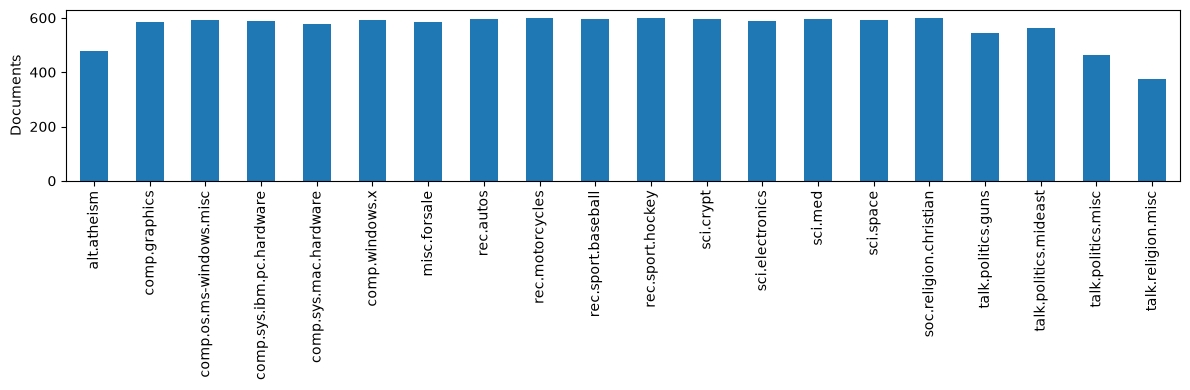

In [41]:
# bar plot으로 labels를 출력하고 클래스 이름으로 표시
class_counts.plot.bar(figsize=(12, 4), ylabel='Documents')
plt.tight_layout()
plt.show()

> **인사이트 :** alt.atheism과 talk.religion.misc, talk.politics.misc 3개의 클래스가 다른 클래스에 비해 부족해보인다. 따라서 분할 방시에 있어서는 비율에 대해서도 고려될 수 있도록 수정한다.

### 문서 길이 분포

NLTK의 `word_tokenize`는 문서를 단어와 문장부호 등 토큰으로 나눈다. `punkt`와 `punkt_tab`은 토큰화용 자료이며, `stopwords`는 정제 단계에서 쓸 불용어 목록이다. 히스토그램은 토큰 개수 범위마다 문서가 몇 건인지 보여준다.

상기 내용이 너무 어려워 쉽게 말하자면 정제 전 EDA를 위해 train 문서마다 NLTK의 word_tokenize()를 적용했다. 공백으로 구분된 단어와 쉼표·느낌표 같은 문장부호가 토큰으로 나뉘며, 문서별 토큰 개수를 세어 길이 분포를 확인했다.

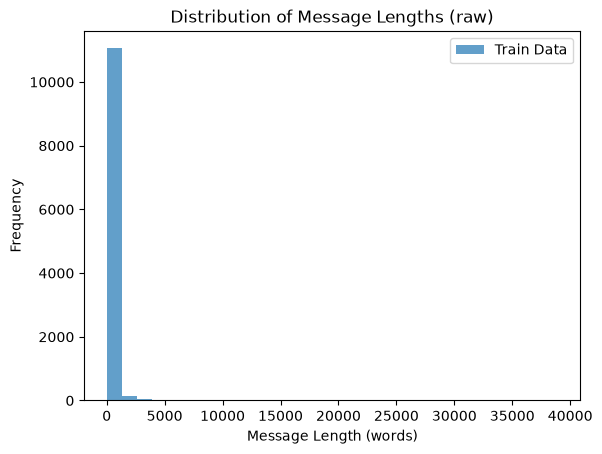

count    11307.000000
mean       261.167330
std       1237.156678
min          0.000000
50%        101.000000
90%        412.000000
95%        705.700000
99%       2307.340000
max      38915.000000
dtype: float64

In [42]:
# 문서 길이 분포는 베이스라인의 히스토그램을 사용
for resource in ("punkt", "punkt_tab", "stopwords"):
    nltk.download(resource, quiet=True)

raw_tokens = [word_tokenize(text) for text in train_inputs]

def show_lengths(tokens, title):
    lengths = [len(doc) for doc in tokens]
    plt.hist(lengths, bins=30, alpha=0.7, label="Train Data")
    plt.xlabel("Message Length (words)")
    plt.ylabel("Frequency")
    plt.legend()
    plt.title(title)
    plt.show()
    display(pd.Series(lengths).describe(percentiles=[0.5, 0.9, 0.95, 0.99]))
    return lengths

raw_lengths = show_lengths(raw_tokens, "Distribution of Message Lengths (raw)")

> **인사이트 :** 50%는 토큰의 중앙값으로 101개의 토근이 있으며, 정제 전을 기준으로 max_len을 설정하기에는 95%를 확인한다. 정제전에는 705가 기준으로 나오고 있다.

### 단어 빈도

`Counter`는 토큰별 등장 횟수를 센다. 빈도 상위 목록은 어떤 단어와 기호가 반복되는지 확인하는 데 쓴다.

In [43]:
# 제일 많이 나오는 단어 확인
def word_counts(tokens):
    return Counter(word for doc in tokens for word in doc)

raw_counts = word_counts(raw_tokens)
display(raw_counts.most_common(20))

[(',', 107788),
 ('.', 101280),
 ('the', 93683),
 ('>', 64363),
 ("'", 59704),
 ('--', 56359),
 ('to', 51196),
 ('AX', 45864),
 ('of', 45761),
 ('and', 39952),
 ('a', 39702),
 (')', 37493),
 ('(', 34521),
 ('I', 34081),
 ('is', 28928),
 ('*', 27982),
 ('in', 27912),
 ('that', 26922),
 (':', 26478),
 ("''", 20818)]

워드클라우드는 자주 나온 토큰을 크게 표시한다. 정확한 횟수는 빈도 목록에서 확인한다.

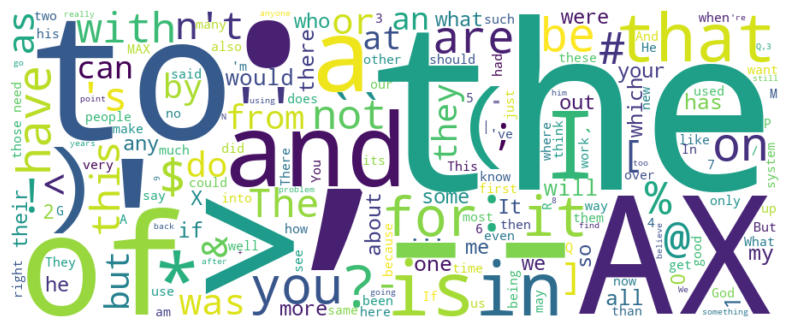

In [44]:
# 워드 클라우드로 시각화
def show_cloud(counts):
    cloud = WordCloud(width=900, height=360, background_color="white", random_state=SEED)
    plt.figure(figsize=(10, 4))
    plt.imshow(cloud.generate_from_frequencies(counts), interpolation="bilinear")
    plt.axis("off")
    plt.show()

show_cloud(raw_counts)

> **인사이트 :** 정제 전 워드클라우드에서 the, to, and 같은 흔한 단어와 >, *, # 같은 기호가 크게 나타났다. 기본 정제를 적용한 뒤 어떤 토큰이 빈도 상위에 남는지 비교한다. 기본 불용어 정제 시, 특수문자는 전부 제거하는 방향을 확인한다.

희귀 단어 비율의 분모는 전체 등장 횟수가 아니라 고유 토큰 수다. 여기서 희귀 단어는 train에서 딱 한 번 나온 토큰이다.

In [45]:
# 1번만 나오는 희귀 단어 확인 및 비율
def singleton_words(counts):
    rare = {word for word, count in counts.items() if count == 1}
    print(f"한 번 나온 단어: {len(rare):,}개 ({len(rare) / max(len(counts), 1):.2%} of vocabulary)")
    return rare

raw_rare = singleton_words(raw_counts)

한 번 나온 단어: 90,083개 (60.71% of vocabulary)


> **인사이트 :** 정제 전 train에서 한 번만 등장한 토큰은 90,083종으로, 전체 고유 토큰의 60.71%였다. 원문 예시에서 어떤 토큰이 한 번만 나왔는지 확인하고, 정제 후 개수와 비율을 비교한다.

In [46]:
# 예시를 print하여 확인하고 문서 리스트로 뽑아두기
rare_documents = [i for i, doc in enumerate(raw_tokens) if raw_rare.intersection(doc)]
for i in rare_documents[:3]:
    print(i, sorted(raw_rare.intersection(raw_tokens[i]))[:8])
    print(train_inputs[i][:300])

0 ['TGO']
: 
: And, while we are on the subject, has a captain ever been traded, 
: resigned, or been striped of his title during the season? Any other 
: team captain trivia would be appreciated.
: 

Luc Robitaille was captain of the Kings the first third of the season,
until The Great One came back from his
1 ['Incredulously', 'Rutin', 'bioflavonoid', 'capillary', 'fragility', 'hemorrhoid-wise', 'hemorrhoids', 'rinds']

Rutin is a bioflavonoid, compounds found (among other places) in the
rinds of citrus fruits.  These have been popular, especially in Europe,
to treat "capillary fragility", and seemingly in even more extreme cases--
a few months ago, a friend was visiting from Italy, and he said that he'd
had hemor
3 [',200mbDISK', '/WAY/', 'S3/928,8mb,15', 'apples/apples', 'expandability', 'functinality']

I would further add that a 486/50,S3/928,8mb,15",200mbDISK is going to cost
/WAY/ more than $900, probably $3,000.  Color makes it not apples/apples too.
Xterminals provide better 

### 어휘 크기

In [47]:
# 고유 단어 수가 몇 개인지 확인하기
print('정제 전 고유 토큰 수', len(raw_counts))

정제 전 고유 토큰 수 148386


### 노이즈 확인

해시(hash)는 문서를 비교할 때 쓰는 고정 길이 지문이다. 이 셀에서는 앞뒤 공백을 제거한 뒤 SHA-256 지문을 만들어 같은 내용이 몇 번 반복됐는지 센다.

In [ ]:
# 빈 문서, 중복 문서를 hash를 사용해서 확인하기
'''
return 으로 계속 돌려줄껀데, 
SHA-256 기능을 쓸 수 있게 해주는 파이썬 기본 모듈
sha256은 글을 받아서 일정 한 길이의 '디지털 지문'을 만드는 방법
text.strip() 본문 앞뒤의 공백과 줄바꿈을 제거한다.
encode("utf-8") 글자를 컴퓨터가 처리할 수 있는 숫자(바이트)로 바꾸는 것
hexdigest() 만들어진 지문을 a3f2같은 문자열로 꺼내줌
'''
def document_hash(text):
    return hashlib.sha256(text.strip().encode("utf-8")).hexdigest()

train_hashes = Counter(map(document_hash, train_inputs)) # map()은 train 글마다 document_hash()를 적용한다.
empty_documents = [i for i, text in enumerate(train_inputs) if not text.strip()]
duplicate_documents = [i for i, text in enumerate(train_inputs)
                       if train_hashes[document_hash(text)] > 1]
print("빈 문서", len(empty_documents))
print("중복 건수(첫 등장 제외, 빈 문서 포함)", sum(n - 1 for n in train_hashes.values()))

빈 문서 306
중복 건수(첫 등장 제외, 빈 문서 포함) 332


> **인사이트 :**
Train 데이터에서 본문이 비어 있거나 공백만 있는 문서가 306건 확인됐다. 헤더·푸터·인용문을 제거하는 과정에서 일부 문서의 본문이 비었을 가능성이 있다. 빈 문서는 본문을 바탕으로 카테고리를 학습하는 데 단서를 주지 못하므로, 제거 전 원문과 비교해 비게 된 원인을 확인한 뒤 학습 데이터에서 제외한다.

분할 간 중복은 같은 본문이 train과 val 또는 test에 걸쳐 있는지 확인하는 점검이다. 세 분할 쌍에서 같은 해시를 가진 비어 있지 않은 고유 문서 수를 센다.

In [53]:
# train/val/test 간 중복도 확인
# 분할 간 누수 점검은 비어 있지 않은 문서의 해시 집합만 사용한다.
hash_sets = {
    name: {document_hash(text) for text in split if text.strip()}
    for name, split in (("train", train_inputs), ("val", val_inputs), ("test", test_inputs))
}
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    print(f"{a}와 {b}에 똑같이 들어 있는 본문: {len(hash_sets[a] & hash_sets[b])} 종류")

train와 val에 똑같이 들어 있는 본문: 18 종류
train와 test에 똑같이 들어 있는 본문: 11 종류
val와 test에 똑같이 들어 있는 본문: 7 종류


> **인사이트 :** 라벨 값도 제외가 되야되기 때문에 해당 추가로 짝지어 비교한다.

In [52]:
print("val 빈 문서:", sum(not text.strip() for text in val_inputs))
print("test 빈 문서:", sum(not text.strip() for text in test_inputs))

val 빈 문서: 95
test 빈 문서: 114


| 데이터 분할 | 빈 문서 수 |
|---|---:|
| train | 306 |
| val | 95 |
| test | 114 |
| **합계** | **515** |

<br>

> **인사이트 :** remove=("headers", "footers", "quotes")를 적용한 뒤의 데이터에서 본문이 비어 있거나 공백, 줄바꿈만 남은 문서는 총 515개이다. 

정규표현식(regex)은 글자 패턴을 찾는 규칙이다. 특수문자·숫자·이메일 주소를 각각 찾아 전체 등장 횟수와 포함된 문서 수를 센다.

In [54]:
# 특수문자, 숫자, 이메일 주소가 얼마나 섞였는지 보기
noise_patterns = {
    "특수문자": re.compile(r"[^\w\s]|_"),
    "숫자": re.compile(r"\d"),
    "이메일": re.compile(r"[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}"),
}
noise_documents = {}
for name, pattern in noise_patterns.items():
    counts = [len(pattern.findall(text)) for text in train_inputs]
    noise_documents[name] = [i for i, count in enumerate(counts) if count]
    print(name, "등장 수", sum(counts), "포함 문서 수", len(noise_documents[name]))

특수문자 등장 수 1036155 포함 문서 수 10975
숫자 등장 수 325509 포함 문서 수 6518
이메일 등장 수 3808 포함 문서 수 1681


노이즈 종류별로 해당 문서의 train 위치를 리스트에 저장해 뒀다. 그중 앞의 두 문서씩 일부를 출력해 실제로 어떤 형태가 섞여 있는지 확인한다.

In [55]:
# 예시를 print하여 확인하고 문서 리스트로 뽑아두기
for name, indices in noise_documents.items():
    for i in indices[:2]:
        print(name, i, train_inputs[i][:300])

특수문자 0 : 
: And, while we are on the subject, has a captain ever been traded, 
: resigned, or been striped of his title during the season? Any other 
: team captain trivia would be appreciated.
: 

Luc Robitaille was captain of the Kings the first third of the season,
until The Great One came back from his
특수문자 1 
Rutin is a bioflavonoid, compounds found (among other places) in the
rinds of citrus fruits.  These have been popular, especially in Europe,
to treat "capillary fragility", and seemingly in even more extreme cases--
a few months ago, a friend was visiting from Italy, and he said that he'd
had hemor
숫자 0 : 
: And, while we are on the subject, has a captain ever been traded, 
: resigned, or been striped of his title during the season? Any other 
: team captain trivia would be appreciated.
: 

Luc Robitaille was captain of the Kings the first third of the season,
until The Great One came back from his
숫자 3 
I would further add that a 486/50,S3/928,8mb,15",200mbDISK is going to c

> **인사이트 :** 헤더·푸터·인용문을 제거한 뒤 빈 문서와 분할 간에 본문이 같은 문서를 확인했다. 추가 정제에서는 본문에 남아 있는 이메일 주소와 특수문자를 제거한다. 숫자는 제품 사양, 버전, 금액처럼 카테고리를 판단하는 데 도움이 되는 정보를 담을 수 있으므로 유지한다.

### n-gram 분석

n-gram은 연달아 등장한 토큰 묶음이다. 여기서는 두 토큰짜리 bigram을 세고, 문서 경계를 넘어 단어쌍을 만들지 않는다.

In [56]:
# 자주 같이 나오는 단어쌍 확인
def top_bigrams(tokens):
    return Counter(pair for doc in tokens for pair in zip(doc, doc[1:])).most_common(20)

display(top_bigrams(raw_tokens))

[(('>', "'"), 49913),
 (('--', '--'), 48522),
 (("'", 'AX'), 45738),
 (('AX', '>'), 45557),
 (('*', '*'), 11685),
 (('of', 'the'), 11142),
 ((',', 'and'), 9700),
 (('.', 'I'), 8136),
 (('in', 'the'), 7273),
 (('.', 'The'), 7112),
 ((',', 'but'), 5334),
 ((',', 'I'), 4565),
 ((')', '.'), 4506),
 (('to', 'the'), 4430),
 ((',', 'the'), 4112),
 (('on', 'the'), 3924),
 (('do', "n't"), 3582),
 (('to', 'be'), 3381),
 (('.', 'It'), 3337),
 (("'", 'MAX'), 3275)]

> **인사이트 :** 불용어 제거 전 조합

[(('>', "'"), 49913),
 (('--', '--'), 48522),
 (("'", 'AX'), 45738),
 (('AX', '>'), 45557),
 (('*', '*'), 11685),
 (('of', 'the'), 11142),
 ((',', 'and'), 9700),
 (('.', 'I'), 8136),
 (('in', 'the'), 7273),
 (('.', 'The'), 7112),
 ((',', 'but'), 5334),
 ((',', 'I'), 4565),
 ((')', '.'), 4506),
 (('to', 'the'), 4430),
 ((',', 'the'), 4112),
 (('on', 'the'), 3924),
 (('do', "n't"), 3582),
 (('to', 'be'), 3381),
 (('.', 'It'), 3337),
 (("'", 'MAX'), 3275)]

### 데이터 확인 이후, 추가 EDA
- alt, comp, misc, rec, sci, soc, talk 라벨 앞에 해당 목록이 보인다. 해당 라벨을 가진 글들을 하나씩 확인해서 어떤 정보를 저렇게 표현했는지 확인한다.<br>

In [40]:
prefix = "rec"  # alt, comp, misc, rec, sci, soc, talk 중 하나
examples_per_label = 2

print(f"===== {prefix} 그룹 =====")

for label_id, label_name in enumerate(target_names):
    if label_name.split(".")[0] != prefix:
        continue

    documents = [
        text.strip()
        for text, label in zip(train_inputs, train_targets)
        if label == label_id and text.strip()
    ]

    print(f"\n[{label_name}] train 글 {len(documents)}편")
    for i, text in enumerate(documents[:examples_per_label], start=1):
        print(f"\n예시 {i}\n{text[:600]}")

===== rec 그룹 =====

[rec.autos] train 글 560편

예시 1
Several chemists already have come up with several substitutes for
R12.  You don't hear about them because the Mobile Air Conditioning Society
(MACS), that is, the people who stand to rake in that $300 to $1000 per
retrofit per automobile, have mounted an organized campaign to squash those
R12 substitutes out of existence if not ban them altogether (on very shaky
technical grounds, at best, on outright lies at worst).

	Does this piss you off?  Yes?  Write a letter to your congressman, to
your senator, to the president, to the EPA, and to the DOT and complain.

Later,

예시 2
Vell...Let's see...vas you muzzah in der passenger seat?  Or vas you muzzah in
der leefing room, vit you fazah?

[rec.motorcycles] train 글 586편

예시 1
"May your skin stick to a frozen bed pan"
  "May your apple juice be mistakenly drawn from the urinalisys
lab"

예시 2
I really didn't mean to imply that my Ninja was any better than a Duc.  
I have to talked to a few Du

> 인사이트 : 카테고리 라벨 앞부분은 대분류이고, 뒤에는 소분류 이다.

| 라벨 앞부분 | 영어 원형 | 한국어로 적으면 |
|---|---|---|
| `alt` | **alternative** | 자유 주제 |
| `comp` | **computer** | 컴퓨터 |
| `misc` | **miscellaneous** | 기타 |
| `rec` | **recreation** | 여가·취미 |
| `sci` | **science** | 과학 |
| `soc` | **social** | 사회·문화 |
| `talk` | **talk** | 토론 |

- 공백만 있는 문서와 원본 문서를 1x2로 출력하여 비교한다. 해당 문서가 학습하는데 카테고리 단서를 주는지 못주는지를 확인하고 제외할지 아닐지를 결정한다.

In [50]:
from html import escape
from IPython.display import HTML, display

# 헤더·푸터·인용문을 제거하기 전 원문을 불러온다.
unfiltered_data = fetch_20newsgroups(subset="all", remove=())

# 두 데이터에서 같은 위치가 같은 문서인지 확인한다.
assert np.array_equal(unfiltered_data.filenames, data.filenames)

# 기존과 같은 조건으로 train 문서가 전체 데이터의 몇 번에 있었는지 찾는다.
train_val_ids, _ = train_test_split(
    np.arange(len(texts)),
    test_size=0.2,
    random_state=SEED,
    stratify=labels,
)
train_ids, _ = train_test_split(
    train_val_ids,
    test_size=0.25,
    random_state=SEED,
    stratify=labels[train_val_ids],
)

# 빈 문서 목록에서 앞의 3개를 비교한다.
for train_pos in empty_documents[:3]:
    original_id = train_ids[train_pos]
    original_text = unfiltered_data.data[original_id]
    current_text = train_inputs[train_pos]
    category = target_names[train_targets[train_pos]]

    print(f"train 위치 {train_pos} | 정답 카테고리 {category}")

    display(HTML(f"""
    <table style="width: 100%; table-layout: fixed;">
      <tr><th>제거 전 원문</th><th>제거 후 본문</th></tr>
      <tr>
        <td style="vertical-align: top;">
          <pre style="white-space: pre-wrap;">{escape(original_text)}</pre>
        </td>
        <td style="vertical-align: top;">
          <pre style="white-space: pre-wrap;">{escape(repr(current_text))}</pre>
        </td>
      </tr>
    </table>
    """))

train 위치 23 | 정답 카테고리 rec.motorcycles


제거 전 원문,제거 후 본문
From: cassidy@elan.rowan.edu (Kyle Cassidy) Subject: Re: Question???? Lines: 11 Nntp-Posting-Host: bizlab37.rowan.edu Organization: Rowan College of New Jersey Distribution: usa In article <1993Apr21.030201.27904@research.nj.nec.com> behanna@syl.nj.nec.com (Chris BeHanna) writes: >In article <1r25ldINN9rp@frigate.cis.ohio-state.edu> fields@cis.ohio-state.edu (jonathan david fields) writes: >>This is probably a stupid question but as I am new to the motorcycle scene >>I don't really know anything about it. What is DoD? > > This has to be a setup. Lookit--same site as Arnie Skurow. probably just want to see how many faq's they'll get. oh well. here goes....,''


train 위치 24 | 정답 카테고리 sci.space


제거 전 원문,제거 후 본문
"From: brody@eos.arc.nasa.gov (Adam R. Brody ) Subject: Re: Conference on Manned Lunar Exploration. May 7 Crystal City Organization: NASA Ames Research Center Distribution: na Lines: 14 prb@access.digex.com (Pat) writes: >AW&ST had a brief blurb on a Manned Lunar Exploration confernce >May 7th at Crystal City Virginia, under the auspices of AIAA. >Does anyone know more about this? How much, to attend???? >Anyone want to go? >pat I got something in the mail from AIAA about it. Cost is $75. Speakers include John Pike, Hohn Young, and Ian Pryke.",'\n\n\n\n'


train 위치 35 | 정답 카테고리 rec.autos


제거 전 원문,제거 후 본문
From: marshatt@feserve.cc.purdue.edu (Zauberer) Subject: Re: WARNING.....(please read)... Organization: Purdue University Can we please stick to AUTOMOTIVE topics . Thank you. Lines: 1,'\n'


> **인사이트 :**
Train에서 본문이 비어 있는 문서 306건을 확인했다. 그중 일부를 제거 전 원문과 비교한 결과, 확인한 예시에서는 카테고리를 추론할 만한 내용이 거의 없었다. 모델에 입력할 본문이 비어 있으므로 해당 문서를 학습 데이터에서 제외한다.

| EDA 항목 | 확인한 내용 | 정제에 반영할 점 |
|---|---|---|
| 문서 길이 | 정제 전 train 문서의 토큰 수 분포를 확인 | 정제 후 train의 길이 분포를 다시 보고 `max_len`을 확인 |
| 워드클라우드 | `the`, `to`, `and` 같은 흔한 단어와 `>`, `*`, `#` 같은 기호 사용진도가 높음 | 기본 영어 불용어와 특수문자를 제거하고, 정제 후 빈도 상위에 무엇이 남는지 비교 |
| 한 번 나온 토큰 | **90,083종**, 전체 고유 토큰의 **60.71%** | 정제 후 개수와 비율을 다시 비교 |
| 빈 문서 | 헤더·푸터·인용문 제거 후 **train 306건, val 95건, test 114건**이 빈 문서가 됨, 확인한 원문 예시에서도 카테고리 단서가 거의 없음 | 세 분할에 같은 기준을 적용해 **빈 본문과 짝이 되는 라벨을 함께 제외**하여 정제하면서 새로 빈 문서가 생기는지도 확인 |
| 분할 간 같은 본문 | `train–val` 18종류, `train–test` 11종류, `val–test` 7종류에서 같은 본문 중복 | 빈 문서와 별개로 같은 글을 학습과 평가에서 다시 보는 일을 피하도록 **분할 간 중복을 따로 처리할 항목**으로 처리 필요 |
| 이메일·특수문자·숫자 | 헤더·푸터·인용문을 뺀 본문에도 남아 있다는 것을 확인, 숫자는 버전, 제품 사양, 금액의 단서가 될 수 있다고 판단, 숫자 외 제거 실시 | **이메일 주소를 통째로 먼저 제거**하고, 특수문자를 공백으로 바꿔. 영문자와 숫자는 보존 |
| 연속 토큰 쌍 | 정제 전 train에서 어떤 토큰이 자주 붙어 나오는지 확인하는 단계 | 정제 후에도 같은 집계를 해서 기호나 흔한 단어 조합이 줄었는지 비교필요 |

따라서 소문자 변환, 이메일 추가 제거, 특수문자 제거, 빈문서 제거가 필요

## 정제 클리닝

불용어는 정제 규칙에서 제거할 단어다. NLTK 영어 목록을 기본으로 쓰고, 추가 목록은 train EDA를 읽은 뒤 채운다.

In [ ]:
# train EDA 검토 후 필요한 단어만 여기에 추가한다.
extra_stopwords = set()
stop_words = set(stopwords.words("english")) | extra_stopwords

`clean_text`는 소문자로 바꾸고 영문자 이외의 문자를 공백으로 바꾼 뒤 불용어를 걸러낸다. 세 분할 모두 같은 함수를 거친다.

In [ ]:
def clean_text(text):
    letters = re.sub(r"[^a-z\s]", " ", text.lower())
    return " ".join(word for word in letters.split() if word not in stop_words)

train_clean, val_clean, test_clean = (
    [clean_text(text) for text in split]
    for split in (train_inputs, val_inputs, test_inputs)
)

## 단어 토큰화

문서 하나를 토큰 리스트 하나로 바꾼다. 이렇게 만든 세 분할의 토큰을 각 임베딩에서 공통으로 사용한다.

In [ ]:
train_sentences = [word_tokenize(text) for text in train_clean]
test_sentences = [word_tokenize(text) for text in test_clean]

In [ ]:
val_sentences = [word_tokenize(text) for text in val_clean]

## 정제 후 EDA

### 클래스 분포

In [ ]:
# 카테고리별로 문서 수가 균형 잡혀있는지 확인
display(class_counts.to_frame('문서 수'))  # 정제 단계에서 문서를 제거하지 않아 클래스별 건수는 같다.

### 문서 길이 분포

In [ ]:
# 문서 길이 분포는 베이스라인의 히스토그램을 사용
clean_lengths = show_lengths(train_sentences, "Distribution of Message Lengths (clean)")

95분위수는 짧은 쪽부터 정렬했을 때 약 95%가 그 이하에 들어오는 길이다. 이 값과 베이스라인의 280을 각각 적용할 때 잘리는 train 문서 비율을 비교한다.

In [ ]:
# max_len을 train 분포로 정할 수 있도록 확인
candidate_max_len = max(1, int(np.ceil(np.percentile(clean_lengths, 95))))
for length in (280, candidate_max_len):
    print(length, f"토큰이 잘리는 train 문서 비율 {np.mean(np.array(clean_lengths) > length):.2%}")

> **인사이트 :** 정제 후 train 길이 분포와 잘리는 문서 비율을 보고 max_len을 정한다.

### 단어 빈도

정제 전과 같은 방식으로 빈도, 워드클라우드, 한 번 나온 토큰을 다시 확인한다.

In [ ]:
# 제일 많이 나오는 단어, 워드 클라우드, 1번만 나오는 희귀 단어 및 비율 확인
clean_counts = word_counts(train_sentences)
display(clean_counts.most_common(20))
show_cloud(clean_counts)
clean_rare = singleton_words(clean_counts)

### 어휘 크기

In [ ]:
# 고유 단어 수가 몇 개인지 확인하기
print('고유 토큰 수', len(raw_counts), '→', len(clean_counts))

### 노이즈 확인

정제 후 토큰이 하나도 남지 않은 문서의 위치를 저장한다. 문서 해시와 정규표현식을 다시 적용해 중복과 노이즈가 얼마나 남았는지 확인한다.

In [ ]:
# 빈 문서, 중복 문서, 특수문자, 숫자, 이메일이 정제 후 얼마나 남았는지 확인
clean_empty_documents = [i for i, doc in enumerate(train_sentences) if not doc]
clean_hashes = Counter(map(document_hash, train_clean))
print("빈 문서", len(empty_documents), "→", len(clean_empty_documents))
print("정제 후 중복 건수(첫 등장 제외, 빈 문서 포함)", sum(n - 1 for n in clean_hashes.values()))
for name, pattern in noise_patterns.items():
    print(name, sum(len(pattern.findall(text)) for text in train_clean))

### n-gram 분석

In [ ]:
# 자주 같이 나오는 단어쌍 확인
display(top_bigrams(train_sentences))

### 전처리 전후 비교

같은 train 문서의 정제 전후를 나란히 확인한다. 여러 조건으로 선택된 문서가 겹치면 `dict.fromkeys`로 문서 위치를 한 번만 남긴다.

In [ ]:
# 노이즈 확인 후 불용어 제거 결과를 보고, 소문자 변환 후 문서 변화 확인
# 예시를 print하여 확인하고 문서 리스트로 뽑아두기
comparison_indices = list(dict.fromkeys(
    clean_empty_documents[:2] + noise_documents["이메일"][:2] + [0, 1]
))
comparison_documents = pd.DataFrame({
    "train 위치": comparison_indices,
    "정제 전": [train_inputs[i] for i in comparison_indices],
    "정제 후": [train_clean[i] for i in comparison_indices],
})
for row in comparison_documents.itertuples(index=False, name=None):
    print(row[0], "\n정제 전:", row[1][:300], "\n정제 후:", row[2][:300])

> **인사이트 :** 줄어든 어휘와 정제 후 비게 된 문서를 살펴보고 불용어를 추가할지 기록한다.

## 공통 통일 항목
### EDA 결과로 정하는 값

`MAX_LEN`은 문서마다 모델에 넣을 토큰 개수다. 짧으면 패딩으로 채우고, 길면 뒷부분을 자른다. OOV는 사전에 없는 토큰이며 1차에서는 패딩과 같은 0번을 사용한다.

In [ ]:
# 분포 확인 후 None을 선택한 정수로 바꾼다.
MAX_LEN = None
PAD_OOV_ID = 0
print("train 95분위 후보", candidate_max_len)

### 학습 조건

배치는 한 번에 처리할 문서 묶음이다. 학습률(`LR`)은 가중치 업데이트의 크기를 조절하며, 에폭은 train 전체를 한 바퀴 학습하는 단위다.

In [ ]:
BATCH_SIZE = 32
LR = 0.005
EPOCHS = 10

### 임베딩별로 달라지는 값

`window`는 주변 단어를 보는 범위, `min_count`는 사전에 포함할 최소 등장 횟수다. `sg=1`은 중심 단어로 주변 단어를 예측하는 Skip-gram이고, `workers=1`은 학습 스레드를 하나로 고정한다.

In [ ]:
TRAIN_EMBED_DIM = 128
GLOVE_DIM = 200
GLOVE_PATH = Path("glove.6B.200d.txt")
GENSIM_OPTIONS = dict(vector_size=TRAIN_EMBED_DIM, window=5, min_count=1, sg=1, seed=SEED, workers=1)

> **인사이트 :** GloVe는 사전학습 자료와 벡터 차원이 다르다. 세 결과를 비교할 때 이 조건을 함께 기록한다.

## 벡터화

임베딩은 토큰을 숫자 벡터로 나타낸다. 사전에서 토큰의 번호를 찾으면 임베딩 행렬의 같은 번호 행에서 벡터를 꺼낼 수 있다.

In [ ]:
from gensim.models import FastText, Word2Vec

if not isinstance(MAX_LEN, int) or MAX_LEN < 1:
    raise ValueError("정제 후 train EDA를 확인하고 MAX_LEN에 양의 정수를 입력하세요.")

def make_embedding(words, vectors):
    vocab = {word: i for i, word in enumerate(words, start=1)}
    matrix = np.zeros((len(vocab) + 1, vectors.shape[1]), dtype=np.float32)
    matrix[1:] = vectors
    return vocab, matrix

Word2Vec은 train 문서에서 가까운 문맥에 등장하는 단어의 벡터를 학습한다.

In [ ]:
w2v = Word2Vec(sentences=train_sentences, **GENSIM_OPTIONS)
embeddings = {"Word2Vec": make_embedding(w2v.wv.index_to_key, w2v.wv.vectors)}
del w2v

FastText는 단어를 구성하는 글자 조각도 학습에 활용한다. 현재 입력 코드에서는 train 사전에 없는 토큰을 공통 규칙에 따라 0으로 매핑한다.

In [ ]:
fasttext = FastText(sentences=train_sentences, **GENSIM_OPTIONS)
embeddings["FastText"] = make_embedding(fasttext.wv.index_to_key, fasttext.wv.vectors)
del fasttext

GloVe는 단어가 함께 등장한 통계로 미리 학습한 벡터를 파일에서 읽는다. 파일에서 train 어휘와 겹치는 단어의 200차원 벡터를 가져온다.

In [ ]:
# Stanford GloVe 6B의 200d 텍스트 파일 경로를 지정한다.
train_vocabulary = set(clean_counts)
glove_vectors = {}
with GLOVE_PATH.open(encoding="utf-8") as glove_file:
    for line in glove_file:
        word, _, coefficients = line.partition(" ")
        if word in train_vocabulary:
            glove_vectors[word] = np.fromstring(coefficients, sep=" ", dtype=np.float32)
if not glove_vectors or any(vector.size != GLOVE_DIM for vector in glove_vectors.values()):
    raise ValueError("GloVe 파일 경로와 200차원 형식을 확인하세요.")
embeddings["GloVe"] = make_embedding(glove_vectors, np.stack(list(glove_vectors.values())))
del glove_vectors

> **인사이트 :** FastText도 공통 사전에 없는 토큰을 0번으로 처리한다. GloVe 사전은 train 어휘와 겹치는 단어만 사용한다.

## 입력 데이터 구성
### 데이터셋

Dataset은 문서 한 건을 고정 길이 정수 배열과 정답 카테고리 번호로 돌려준다. 앞의 `MAX_LEN`개 토큰을 번호로 바꾸고 남은 자리를 0으로 채운다.

In [ ]:
class TextEmbeddingDataset(Dataset):
    def __init__(self, tokens, labels, word2idx, max_len):
        self.inputs = torch.full((len(tokens), max_len), PAD_OOV_ID, dtype=torch.long)
        self.labels = torch.as_tensor(labels, dtype=torch.long)
        for i, doc in enumerate(tokens):
            ids = [word2idx.get(word, PAD_OOV_ID) for word in doc[:max_len]]
            self.inputs[i, :len(ids)] = torch.tensor(ids, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.inputs[idx], self.labels[idx]

### 데이터 로더

DataLoader는 Dataset에서 여러 문서를 꺼내 배치로 묶는다. `shuffle`은 순서를 섞는 옵션으로 train에만 적용한다. test 로더는 최종 평가 셀에서 만들도록 되어 있다.

In [ ]:
def make_loader(tokens, labels, vocab, *, shuffle=False):
    dataset = TextEmbeddingDataset(tokens, labels, vocab, MAX_LEN)
    generator = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, generator=generator)

def make_train_val_loaders(vocab):
    return (
        make_loader(train_sentences, train_targets, vocab, shuffle=True),
        make_loader(val_sentences, val_targets, vocab),
    )

## 모델 구현

양방향 LSTM은 토큰을 앞에서 뒤로, 뒤에서 앞으로 각각 읽는다. 마지막 층의 두 은닉 상태(문서 요약값)를 이어 붙여 20개 클래스 점수로 바꾼다. `dropout`은 학습 중 일부 신호를 무작위로 끄고, `freeze=False`는 임베딩도 함께 업데이트한다.

In [ ]:
HIDDEN_DIM = 128
OUTPUT_DIM = len(target_names)

class EmbeddingLSTM(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim, output_dim, num_layers=2, dropout=0.5):
        super().__init__()
        weights = torch.tensor(embedding_matrix, dtype=torch.float32)
        self.embedding = nn.Embedding.from_pretrained(weights, freeze=False, padding_idx=PAD_OOV_ID)
        self.lstm = nn.LSTM(
            weights.shape[1], hidden_dim, num_layers=num_layers,
            batch_first=True, dropout=dropout, bidirectional=True,
        )
        self.fc = nn.Linear(hidden_dim * 2, output_dim)

    def forward(self, x):
        embedded = self.embedding(x)
        _, (hidden, _) = self.lstm(embedded)
        last_layer = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.fc(last_layer)

## 학습 및 평가
### 디스코드 알림

웹훅(webhook)은 Discord 채널에 알림을 보내는 주소다. 환경변수 `DISCORD_WEBHOOK_URL`에 설정하면 모델 학습 완료 시 알림을 보낸다.

In [ ]:
import json
import urllib.request

def notify_discord(message):
    webhook = os.environ.get("DISCORD_WEBHOOK_URL")
    if not webhook:
        return
    payload = json.dumps({"content": message}).encode("utf-8")
    request = urllib.request.Request(
        webhook, data=payload, headers={"Content-Type": "application/json"}
    )
    try:
        with urllib.request.urlopen(request, timeout=8):
            pass
    except (OSError, ValueError) as error:
        print("Discord 알림 실패:", type(error).__name__)

### 학습 및 평가 함수

`train_epoch`는 배치마다 예측, 손실 계산, 역전파, 가중치 업데이트를 수행한다. `tqdm`은 배치 진행률을 표시한다.

In [ ]:
def train_epoch(model, loader, optimizer, loss_fn, description):
    model.train()
    loss_sum = 0.0
    for inputs, targets in tqdm(loader, desc=description, leave=False):
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(inputs), targets)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(targets)
    return loss_sum / len(loader.dataset)

`evaluate`는 평가 모드에서 가중치를 고정한 채 손실과 정확도를 계산한다. `argmax`는 점수가 가장 높은 클래스 번호를 고른다.

In [ ]:
@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    loss_sum = 0.0
    actual, predicted = [], []
    for inputs, targets in loader:
        logits = model(inputs.to(device))
        loss_sum += loss_fn(logits, targets.to(device)).item() * len(targets)
        actual.extend(targets.tolist())
        predicted.extend(logits.argmax(dim=1).cpu().tolist())
    return {
        "loss": loss_sum / len(loader.dataset),
        "accuracy": float(np.mean(np.equal(actual, predicted))),
        "actual": actual,
        "predicted": predicted,
    }

def report(scores, as_dict=False):
    return classification_report(
        scores["actual"], scores["predicted"], labels=list(range(OUTPUT_DIM)),
        target_names=target_names, digits=3, zero_division=0, output_dict=as_dict,
    )

### 베이스라인 3종 학습

Adam은 기울기를 이용해 가중치를 업데이트하는 옵티마이저다. `CrossEntropyLoss`는 클래스 점수와 정답 번호를 비교한다. 검증 손실이 가장 낮을 때의 가중치 파일을 체크포인트로 저장한다.

In [ ]:
def fit_baseline(name, vocab, matrix):
    seed_everything(SEED)
    model = EmbeddingLSTM(matrix, HIDDEN_DIM, OUTPUT_DIM).to(device)
    train_loader, val_loader = make_train_val_loaders(vocab)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.CrossEntropyLoss()
    checkpoint_dir = Path("checkpoints")
    checkpoint_dir.mkdir(exist_ok=True)
    checkpoint = checkpoint_dir / f"baseline_{name.lower()}.pt"
    history = []
    best_loss = float("inf")
    best_epoch = None
    for epoch in range(1, EPOCHS + 1):
        train_loss = train_epoch(model, train_loader, optimizer, loss_fn, f"{name} {epoch}/{EPOCHS}")
        scores = evaluate(model, val_loader, loss_fn)
        history.append(dict(epoch=epoch, train_loss=train_loss,
                            val_loss=scores["loss"], val_accuracy=scores["accuracy"]))
        print(name, epoch, f"train={train_loss:.4f} val={scores['loss']:.4f} acc={scores['accuracy']:.3f}")
        if scores["loss"] < best_loss:
            best_loss, best_epoch = scores["loss"], epoch
            torch.save(model.state_dict(), checkpoint)
    if best_epoch is None:
        raise RuntimeError(f"{name}: 검증 손실이 유한한 에폭이 없습니다.")
    model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
    scores = evaluate(model, val_loader, loss_fn)
    notify_discord(f"{name} 학습 완료 | 최적 에폭 {best_epoch} | val 정확도 {scores['accuracy']:.3f}")
    return dict(history=pd.DataFrame(history), best_epoch=best_epoch,
                scores=scores, checkpoint=checkpoint)

runs = {}
for name, (vocab, matrix) in embeddings.items():
    runs[name] = fit_baseline(name, vocab, matrix)

### 손실 곡선 비교

학습 손실과 검증 손실을 임베딩별로 비교한다. train 손실은 계속 줄고 val 손실이 올라가는 시점이 있으면 과적합 가능성을 살펴본다.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for axis, metric in zip(axes, ("train_loss", "val_loss")):
    for name, run in runs.items():
        history = run["history"]
        axis.plot(history["epoch"], history[metric], marker="o", label=name)
    axis.set(xlabel="Epoch", ylabel="Cross-entropy loss", title=metric)
    axis.legend()
plt.tight_layout()
plt.show()

### 검증 분류 리포트

Precision은 해당 클래스로 예측한 문서 중 맞힌 비율이고, recall은 실제 그 클래스 문서 중 맞힌 비율이다. F1은 둘의 조화평균이다. Macro 평균은 모든 클래스를 같은 비중으로, weighted 평균은 클래스별 문서 수에 비례해 반영한다.

In [ ]:
for name, run in runs.items():
    print(name, "최소 val loss 에폭", run["best_epoch"])
    print(report(run["scores"]))

> **인사이트 :** train과 val 손실이 갈라지는 에폭, 검증 정확도와 클래스별 F1이 다르게 움직이는 경우를 기록한다.

## 계획서 결과 기록
### 베이스라인 3종 비교 (val 기준)

> 조건: 시드 42, 배치 32, max_len ○○, 에폭 10, lr 0.005 (3종 동일)

| 임베딩 | 차원 | 사전 크기 | OOV 비율 | 마지막 train loss | val 정확도 | 최소 val loss | 최고 val 정확도 | 최적 에폭 | macro F1 (EDA 이후 선택) | 메모 |
|---|---|---|---|---|---|---|---|---|---|---|
| Word2Vec | | | | | | | | | | |
| FastText | | | | | | | | | | |
| GloVe | | | | | | | | | | |


OOV 비율은 길이 제한을 적용한 뒤 검증 토큰 중 각 임베딩 사전에 없는 토큰의 비율이다. 표의 최고 val 정확도는 전체 에폭에서 구하고, val 정확도와 macro F1은 최소 val loss 에폭의 모델에서 구한다.

In [ ]:
def oov_rate(tokens, vocab):
    model_tokens = (word for doc in tokens for word in doc[:MAX_LEN])
    total, missing = 0, 0
    for word in model_tokens:
        total += 1
        missing += word not in vocab
    return missing / total if total else float("nan")

print(f"시드 {SEED} / 배치 {BATCH_SIZE} / max_len {MAX_LEN} / 에폭 {EPOCHS} / lr {LR}")
rows = []
for name, run in runs.items():
    vocab, matrix = embeddings[name]
    history, scores = run["history"], run["scores"]
    rows.append({
        "임베딩": name, "차원": matrix.shape[1], "사전 크기": len(vocab),
        "val OOV 비율": oov_rate(val_sentences, vocab),
        "마지막 train loss": history["train_loss"].iloc[-1],
        "val 정확도": scores["accuracy"], "최소 val loss": scores["loss"],
        "최고 val 정확도": history["val_accuracy"].max(), "최적 에폭": run["best_epoch"],
        "macro F1": report(scores, as_dict=True)["macro avg"]["f1-score"], "메모": "",
    })
baseline_results = pd.DataFrame(rows)
display(baseline_results.round(4))

> **인사이트 :** val 정확도와 macro F1은 최소 val loss 체크포인트 기준이다. OOV 비율은 길이 제한 이후의 실제 입력 토큰 기준으로 센다.

## 실험계획서

> **인사이트 :** EDA와 검증 결과를 확인한 뒤 작성한다.

## xx차 실험 결과 기록

| 항목 | 예시 | 이번 실험 기록 |
| :--- | :--- | :--- |
| **실험 번호** | 0 (베이스라인) | |
| **임베딩** | Word2Vec / FastText / GloVe | |
| **바꾼 것** | 없음 / lr 0.005 → 0.001 | |
| **고정 조건** | 시드 42, 배치 32, max_len 등 | |
| **결과** | val 정확도, loss 흐름, F1 등 | |
| **메모** | 느낀 점, 이상한 점 | |

> **인사이트 :**

## 최종 선발 및 최종 평가

val 결과와 실험 기록을 보고 모델을 확정한 다음, 이 코드의 주석을 직접 풀어 test를 한 번 평가한다.

In [ ]:
# 검증과 실험을 마친 뒤 선택한 모델명으로 변경한다.
# FINAL_MODEL = None
# if FINAL_MODEL is not None and "final_test_scores" not in globals():
#     final_vocab, final_matrix = embeddings[FINAL_MODEL]
#     final_model = EmbeddingLSTM(final_matrix, HIDDEN_DIM, OUTPUT_DIM).to(device)
#     final_model.load_state_dict(torch.load(
#         runs[FINAL_MODEL]["checkpoint"], map_location=device, weights_only=True
#     ))
#     test_loader = make_loader(test_sentences, test_targets, final_vocab)
#     final_test_scores = evaluate(final_model, test_loader, nn.CrossEntropyLoss())
#     print(FINAL_MODEL, "test 정확도", final_test_scores["accuracy"])
#     print(report(final_test_scores))